# Telco Customer Churn

### Created by: Group Beta (Eddy Jusuf & Siti Khoiriyah)

### **Notebook Contents**

1. Business Process Understanding
2. Data Understanding
3. Data Cleaning
4. Exploratory Data Analysis
5. Machine Learning (Methodology: Modeling/Analysis)
6. Conclusion and Recommendation

****

# ***1. Business Process Understanding***

### ***1.1 Context***

Sebuah perusahaan telekomunikasi (telco) yang berlokasi di Amerika Serikat ingin melakukan analisa terhadap pelanggan (customer subscriber) perusahaannya dan ingin menganalisa ciri khas customer yang berhenti berlangganan (churn). Perusahaan telco tersebut menawarkan berbagai jasa antara lain: PhoneService (saluran telpon rumah) and InternetServices (layanan internet) yang akan di jelaskan lebih lanjut di bawah ini. 

Kami sebagai Data Consultant telah dikontrak oleh perusahaan telco tersebut untuk menganalisa data-data yang terkumpul sehabis internal audit mereka. Internal audit data tersebut didapat dari kuartal 3 (Q3) tahun 2019 dan seluruh datanya adalah berdasarkan data internal perusahaan telco ini saja, bukan gabungan dari perusahaan-perusahaan lain.
(ref: https://community.ibm.com/community/user/blogs/steven-macko/2019/07/11/telco-customer-churn-1113)

Sangat diharapkan data-data yang terkumpul sehabis internal audit, dan digunakannya machine learning (ML) diharapkan dapat membuahkan insights kepada demographic/ciri khas seperti apa customer baru yang akan di target pada marketing campaign selanjutnya. Dengan adanya insights target demographic/ciri khas diharapkan biaya marketing di masa mendatang dapat lebih tepat sasaran, lebih terfokus dan lebih ditekan.

Target
- 0: Not Churn (Continue Service)
- 1: Churn (Cancel Service)

### ***1.2 Problem Statement***

Biaya untuk menarik pelanggan baru adalah suatu resources yang terbatas, tentu perusahaan telco ini ingin mengurangi pelanggan yang putus berlangganan (churn). Berdasarkan data internal audit churn rate pada kuartal 3 tahun 2019 adalah 26%. Mengingat biaya agency atau freelancer mulai dari $50-150 per jam hingga biaya campaign bulanan $300-$2000 semua berdampak pada berapa banyak biaya yang dikeluarkan hanya untuk mendapatkan satu pelanggan baru. Maka churn rate sangat diharapkan dapat turun ke bawah 10%. Dampak turunannya ini akan sangat meningkatkan efisiensi biaya agency atau freelancer yang bisa mencapai puluhan ribu hingga ratusan ribu dollar. 

Diharapkan dengan studi kasus dengan machine learning, dapat ditemukannya insights pada alasan-alasan pelanggan yang putus berlangganan. 

Pertanyaan-pertanyaan dibawah ini akan dicoba untuk menjawab studi kasus dengan Machine Learning:
- Faktor-faktor demographic eg. Gender (Jenis Kelamin), SeniorCitizen (Lansia), Partner (Pasangan), Dependents (Tanggungan) yang mempunyai dampak tinggi terhadapat churn rate. 
- Faktor-faktor lain seperti tenure (lamanya berlangganan), Internet/Phone Service eg. PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling, PaymentMethod, MonthlyCharges, TotalCharges juga akan dianalisa mana yang mempunyai dampak tinggi terhadap churn rate.

Maka pada akhirnya dalam marketing campaign untuk menarik pelanggan baru di masa mendatang, dapat ditargetkan ke demographic calon-calon customer berdasarkan insights tersebut. 

### ***1.3 Goals***
- Mengurangi tingkat churn rate dibawah 10% per kwartal 3 bulan dengan menggunakan model machine learning (ML) yang telah di buat. Dengan tingkat churn rate dibawah 10% akan sangat menghemat biaya agency atau freelancer untuk mendapatkan pelanggan baru dan akhirnya dapat membantu benchmark profit perusahaan. Data 10% tersebut didapat dari penelitian artikel https://djournals.com/klik/article/download/829/596/3804 yang mengindikasikan churn rate per bulan di industri telekomunikasi di Amerika adalah 2-3% (Atau sekitar 10% per kwartal 3 bulan)
- Mampu memprediksi variabel-variable atau sasaran demographic potensi customer yang akan ditargetkan. Ini juga akan meningkatkan efisiensi biaya marketing campaign dan mengurangi tingkat kebocoran.
- Mendukung strategi bisnis dengan memberikan daftar pelanggan berisiko tinggi yang siap ditindaklanjuti untuk retensi.

### ***1.4 Metric Evaluation***

Dalam penentuan metric yang digunakan untuk studi kasus ini, akan dilihat dari komponen Confusion Matrix (TP, FP, TN dan FN). Terakit dengan kasus tersebut maka FN (False Negatives) - pelanggan churn tapi tidak terdeteksi - kerugian besar dan permanen. Bila dibanding dengan FP (False Positives) - pelanggan loyal tapi tetap diberikan diskon atau promo - biaya relatif kecil dan terkontrol. Bila dilihat dari sisi bisnis, FN jauh lebih mahal dari FP. 

Menurut artikel dalam https://tridenstechnology.com/telecom-churn/ data APRU (average revenue per customer - pendapatan per pelanggan) adalah $50 per perlanggan per bulan. Dan biaya retensi untuk satu pelanggan adalah rata-rata $50 (misalkan dengan pemberian gratis langganan 1 bulan atau voucher diskon). Untuk medapatkan pelanggan baru cost nya 6-7x daripada mempertahankan pelanggan loyal - yang artinya memakan biaya $300-350 untuk mendapatkan pelanggan baru.

Singkatnya komponen - komponen dalam confusion_matrix antara lain: 
- TP (True Positives) - pelanggan prediksi churn dan benar churn - retensi tepat sasaran
- FP (False Positives) - prediksi churn tapi loyal - dampak biaya promo
- FN (False Negatives) - tidak terdeteksi tapi churn - kehilangan revenue - Yang difokuskan pada studi kasus ini
- TN (True Negatives) - loyal dan diprediksi loyal - tidak ada kerugian biaya

Metrik yang berhubungan erat dengan komponen confusion matrix FN adalah:
- F2-Score - Recall diberikan bobot 4x dibanding Precision - F2 memberi bobot lebih pada penurunan FN.


Sangat diharapkan model yang telah dibuat dapat meminimalisasi False Negatives (Menekan biaya marketing yang terbuang sia-sia) dan False Positives. Metric yang akan digunakan adalah F2 Score.

### ***1.5 Batasan Masalah (Project Limitation)***
- Target Data Imbalance (Data yang dipelajari jauh lebih sedikit). 
- Jumlah pelanggan yang tersedia hanya sekitar 7000 pelanggan. Jumlah ini diasumsikan sebagai sample dari keseluruhan data pelanggan yang ada. Dengan kata lain data tersebut kurang menjadi representasi menyeluruh dengan perkiraan jumlah pelanggan perusahaan telco yang secara real.

### ***1.6 Analytic Approach***

Project ini akan terbagi dalam tahap-tahap berikut:
- Load & Explore Data
- Data Understanding
- Data Cleaning (EDA)
- Split Train/Test
- Preprocessing
- Modelling
- Evaluation
- Hyperparameter Tuning
- Confusion Matrix
- Feature Importance
- Model Deployment

# ***2. Data Understanding***

In [137]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn import metrics
from sklearn.model_selection import train_test_split

# Preprocessing
import category_encoders as ce
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler, PolynomialFeatures
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from imblearn.pipeline import Pipeline as ImbPipeline


# Model
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.ensemble import AdaBoostClassifier, AdaBoostRegressor
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
from xgboost.sklearn import XGBClassifier
from lightgbm import LGBMClassifier

# Metric
from sklearn.model_selection import cross_val_score, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score, precision_score, classification_report, f1_score, make_scorer, fbeta_score
from sklearn.metrics import roc_curve, roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay, average_precision_score, precision_recall_curve
from scipy.stats import randint, uniform
from scipy.stats import kruskal, mannwhitneyu

# Pickle
import pickle
import warnings
warnings.filterwarnings("ignore")
pd.set_option('display.max_columns', None)

# Steamlit
import streamlit as st


Dataset source: https://www.kaggle.com/datasets/blastchar/telco-customer-churn

Dataset berisi informasi sebagai berikut:

Features 

Customer profile
-	customerID
-	gender (jenis kelamin)
-	SeniorCitizen (lansia)
-	Dependents (memiliki tanggungan eg. anak, pasangan, orang tua)
-	tenure (lamanya menjadi pelanggan)

Telco data
-   PhoneService (memiliki saluran telpon)
-   MultipleLines (memiliki beberapa saluran telpon)
-   InternetService (memiliki jasa internet)
-   OnlineSecurity (pelanggan online security)
-   OnlineBackup (pelanggan online backup)
-   DeviceProtection (memiliki jasa proteksi alat)
-   TechSupport (pelanggan technical support)
-   StreamingTV (pelanggan streaming tv)
-   StreamingMovies (pelanggan streaming movies)
-   Contract (tipe kontrak)
-   PaperlessBilling (tagihan bentuk elektronik)
-   PaymentMethod (metode pembayaran)
-   MonthlyCharges (tagihan bulanan)
-   TotalCharges (totak tagihan bulanan)
-   Churn (putus berlangganan sejak sebulan lalu)

### ***2.1 Load & Explore Data***

In [73]:

df = pd.read_csv(r'C:\Users\ASUS\OneDrive\Desktop\Purwadhika\Project Final\WA_Fn-UseC_-Telco-Customer-Churn.csv')
print(df.shape)
df.head()


(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### ***2.2 Data Info***

In [74]:
df.info() 


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [75]:
df.describe(include='all')

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,6531,2
top,3186-AJIEK,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,20.2,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


### ***2.3 Analisa Data Understanding***

#### **1). SeniorCitizen**
* Nilai mean = 0.16 → hanya sekitar 16% pelanggan adalah lansia.
* Median = 0 dan nilai pada kuartil (25%, 50%, 75%) semuanya 0 → menunjukkan ketidakseimbangan kelas (mayoritas bukan lansia).
* Variasi kecil karena variabel ini biner (0 = bukan lansia, 1 = lansia).

#### **2). tenure**
* Rata-rata 32 bulan, cukup moderat.
* Tenure minimum = 0 → ada pelanggan yang baru bergabung.
* Tenure maksimum = 72 → ada pelanggan sangat loyal, sudah 6 tahun berlangganan.
* Standar deviasi besar (24.55) → variasi tinggi pada durasi pelanggan bertahan.

#### **3). MonthlyCharges**
* Rata-rata $64.76, median $70.35 → median lebih tinggi dari mean menunjukkan distribusi condong ke kiri (beberapa pelanggan membayar sangat rendah).
* Minimum = $18.25, maksimum = $118.75 → rentang harga besar → menunjukkan paket dan layanan yang beragam.
* Standar deviasi relatif tinggi (30.09).

| Fitur              | Temuan Utama                          | Potensi Pengaruh Churn                                    |
| ------------------ | ------------------------------------- | --------------------------------------------------------- |
| **SeniorCitizen**  | Mayoritas bukan lansia (84%)          | Kelompok minoritas → cek apakah lansia churn lebih tinggi |
| **tenure**         | Variasi tinggi, banyak pelanggan baru | Tenure rendah → risiko churn lebih tinggi                 |
| **MonthlyCharges** | Tarif sangat bervariasi (18–118)      | Tarif tinggi → sering memicu churn                        




## ***3. Data Cleaning***  

In [76]:
df.isna().sum() 

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Tidak ada NaN, tidak perlu melakukan data imputer

In [77]:
df.isnull().sum() 

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

- Semua kolom tidak memiliki *missing value*
- Dataset bersih

### ***3.1 Analisis SeniorCitizen***

In [78]:
df['SeniorCitizen'].value_counts() 

SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

In [79]:

df['SeniorCitizen'] = np.where(df['SeniorCitizen']== 1,'Yes','No')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


- Nilai 1 → "Yes" (SeniorCitizen)
- Nilai 0 → "No" (Bukan SeniorCitizen)

### ***3.2 Analisis Perubahan TotalCharges***

In [80]:
pd.to_numeric(df["TotalCharges"], errors="coerce").isna().sum()


np.int64(11)

In [81]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [82]:
df['TotalCharges'].isna().sum() 

np.int64(11)

Setelah konversi data dari kategorikal ke numerikal, terdapat 11 baris data yang mempunyai value NaN

In [83]:
df[df['TotalCharges'].isna()].shape

(11, 21)

TotalCharges yang mempunyai value NaN masih terdapat 11 baris di dalam 21 kolom

In [84]:
df["TotalCharges"] = df["TotalCharges"].fillna(0) 

- Missing Value pada df['TotalCharges'] diisi dengan value = 0
- Pelanggan baru (tenure = 0) belum mempunyai total biaya

### ***3.3 Analisis Tenure***

In [85]:
df[df['tenure']== 0]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,No,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,0.0,No
753,3115-CZMZD,Male,No,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,0.0,No
936,5709-LVOEQ,Female,No,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,0.0,No
1082,4367-NUYAO,Male,No,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,0.0,No
1340,1371-DWPAZ,Female,No,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,0.0,No
3331,7644-OMVMY,Male,No,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,0.0,No
3826,3213-VVOLG,Male,No,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,0.0,No
4380,2520-SGTTA,Female,No,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,0.0,No
5218,2923-ARZLG,Male,No,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,0.0,No
6670,4075-WKNIU,Female,No,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,0.0,No


Menganalisa value tenure yang bernilai "0"

In [86]:
df[df['tenure']== 0].shape

(11, 21)

In [87]:
(df['tenure']== 0).sum() 

np.int64(11)

- Terlihat kalau tenure = 0 bulan terdapat 11 baris. 
- Baris ini mengindikasikan kalau 11 baris data tersebut mempunyai TotalCharges = 0

In [88]:
((df['tenure']== 0).sum()/df['tenure'].count()) * 100



np.float64(0.1561834445548772)

Untuk menghindari error pada saat menjalankan ML method, maka 11 baris data NaN tersebut akan diisi dengan value = 0 (0,15% data pelanggan yang terdampak)

In [89]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

### ***3.4 Data Duplicate***

In [90]:
df.duplicated().sum() 

np.int64(0)

Tidak terdapat duplicated data dalam dataframe tersebut

### ***3.5 Analisa Kolom Target : Churn Rate***

In [91]:
df['Churn'] = np.where(df['Churn']=='Yes',1,0)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


target: Churn --> no mejadi '0' dan yes menjadi '1'

In [92]:
df['Churn'].value_counts()/len(df)*100

Churn
0    73.463013
1    26.536987
Name: count, dtype: float64

- Imbalance data (data tidak seimbang No: 73.5% vs Yes: 26.5%) 
- Perlu penanganan SMOTE, RandomOverSampler, RandomUnderSampler.

#### ***3.5.1 Distribusi Target Churn setelah perbaikan***

In [93]:
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True))

Churn
0    5174
1    1869
Name: count, dtype: int64
Churn
0    0.73463
1    0.26537
Name: proportion, dtype: float64


### ***3.6 Pembagian Numerikal kolom dan Kategorikal kolom***

In [94]:
numeric_cols = df[['tenure','MonthlyCharges','TotalCharges']]
categorical_cols_temp = df.select_dtypes(include=["object"]).columns
categorical_cols = categorical_cols_temp.drop('customerID')

In [95]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   object 
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


#### ***3.6.1 Kolom Kategorikal***

In [96]:
print(list(categorical_cols))

['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


Kolom kategorikal meliputi :
- gender
- SeniorCitizen 
- Partner 
- Dependents 
- PhoneService 
- MultipleLines
- InternetService
- OnlineSecurity
- OnlineBackup
- DeviceProtection
- TechSupport
- StreamingTV
- StreamingMovies
- Contract
- PaperlessBilling
- PaymentMethod

#### ***3.6.2 Kolom Numerikal***

In [97]:
print(list(numeric_cols))

['tenure', 'MonthlyCharges', 'TotalCharges']


Kolom Numerikal meliputi :
- tenure
- MonthlyCharges
- TotalCharges

Data understanding untuk 'df'

- df.info() menunjukan terdapatnya 7043 pelanggan dan 21 variable.
- Tidak terdapat missing values pada seluruh baris maupun kolom.
- Data format pada TotalCharges berbentuk object(string) dan akan diubah ke bentuk int64(numerikal). Bentuk data sebagai object menandakan kemungkinan ada karakter non-nummerik
- Kolom SeniorCitizen dengan value 0/1 kemungkinan bentuk kategorikal bukan numerikal menandakan yes/no
- Bisa dilihat kolom Numerikal antara lain: SeniorCitizen, tenure, MonthlyCharges
- Dan kolom kategorikal antara lain: customerID, gender, Partner, Dependents, PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, Device Protection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling, PaymentMethod, TotalCharges, Churn

## ***4. EDA (Exploratory Data Analysis)***  

### ***4.1 Pemisahan features kolom dibagi menjadi 5 bagian :***
***demographic_cols, phone_int_service_cols, online_support_cols, streaming_cols, finance_cols***

In [98]:
demographic_cols = df[['gender','SeniorCitizen','Partner','Dependents']]
phone_int_service_cols = df[['PhoneService','MultipleLines','InternetService']]
online_support_cols = df[['OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport']]
streaming_cols = df[['StreamingTV','StreamingMovies']]
finance_cols = df[['Contract','PaperlessBilling','PaymentMethod']]

### ***4.2 Analisa Demographic Kolom***

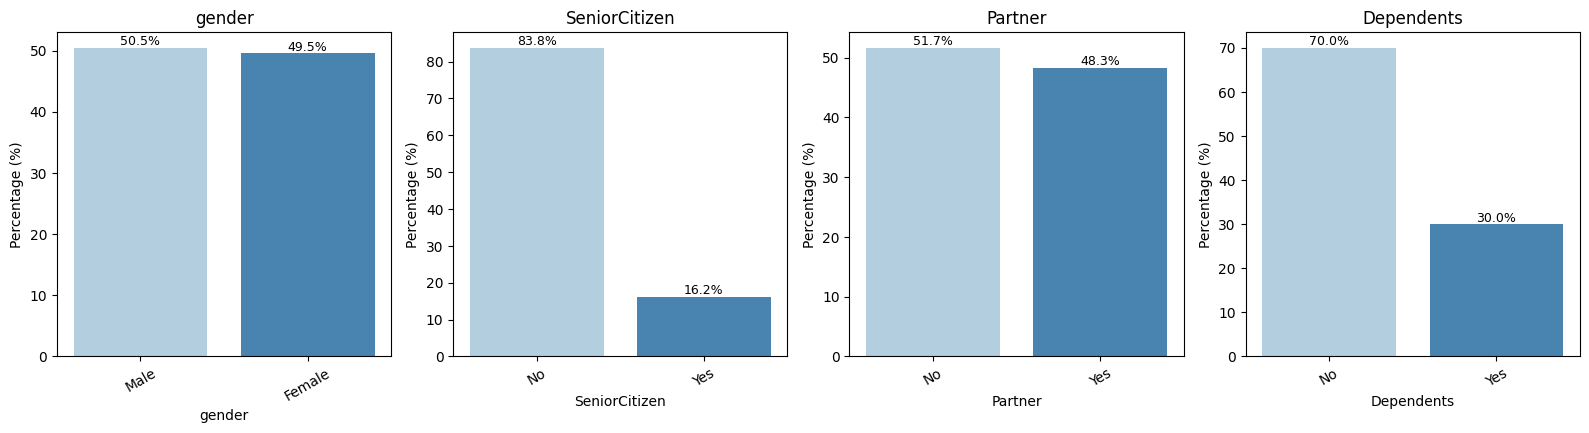

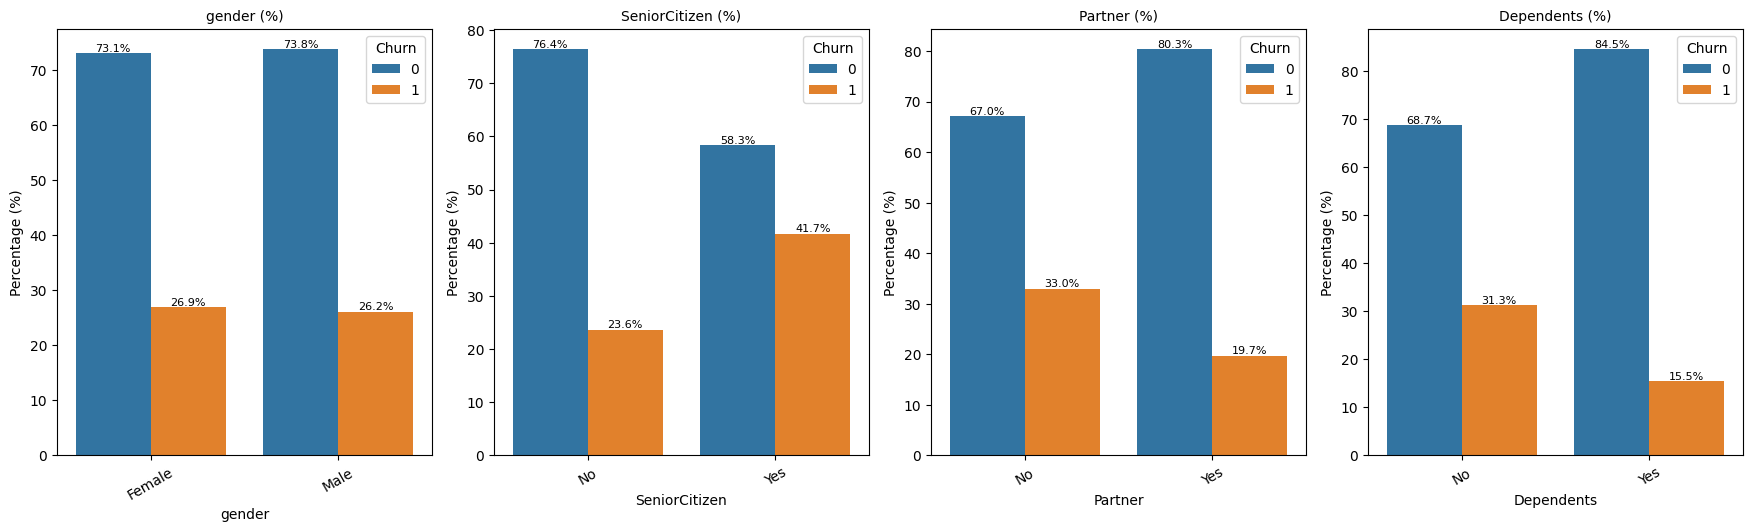

In [99]:
plt.figure(figsize=(16, 20))

for i, col in enumerate(demographic_cols, 1):
    plt.subplot(5, 4, i)

    # hitung persentase
    pct = df[col].value_counts(normalize=True) * 100

    ax = sns.barplot(x=pct.index, y=pct.values, palette="Blues")

    # label persen
    for p in ax.patches:
        ax.annotate(
            f"{p.get_height():.1f}%",
            (p.get_x() + p.get_width()/2, p.get_height()),
            ha="center", va="bottom", fontsize=9
        )

    plt.title(col)
    plt.ylabel("Percentage (%)")
    plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

# Plot Demographic Kolom vs Churn Rate

plt.figure(figsize=(22, 20))
rows, cols = 4, 5

for i, col in enumerate(demographic_cols, 1):
    plt.subplot(rows, cols, i)

    # Hitung persentase per kategori & churn
    percent_df = (
        df.groupby([col, "Churn"], as_index=False)
          .size()
    )

    percent_df["percentage"] = (
        percent_df
        .groupby(col)["size"]
        .transform(lambda x: 100 * x / x.sum())
    )

    ax = sns.barplot(
        data=percent_df,
        x=col,
        y="percentage",
        hue="Churn"
    )

    # Tambahkan label percentage di atas bar
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.1f%%",
            label_type="edge",
            fontsize=8
        )

    plt.title(f"{col} (%)", fontsize=10)
    plt.ylabel("Percentage (%)")
    plt.xticks(rotation=30)

plt.tight_layout()
plt.show()



#### ***4.2.1 Analisa plot kategorikal demographic kolom***

- Chart Gender: Distribusi antara male dan female cukup seimbang. Fitur ini kecil berpengaruh pada churn rate.
- Chart SeniorCitizen: Pelanggan bukan lansia cenderung mempunyai churn rate yang jauh lebih tinggi dibanding pelanggan lansia
- Chart Partner: Distribusi antara pelanggan yang mempunyai partner atau tidak cukup seimbang meskipun yang tidak mempunyai partner cenderung sedikit lebih tinggi churn ratenya.
- Chart Dependents: Pelanggan tanpa dependents cenderung lebih sering churn.

#### ***4.2.2 Analisa Demographic Kolom by Churn Rate***

- Dapat dilihat dari chart Gender tidak ada perbedaan jauh untuk churn rate antara gender pelanggan ataupun pelanggan yang memiliki/tidak memiliki beberapa line telpon.
- Dapat dilihat dari chart SeniorCitizen, pelanggan lansia cenderung memiliki churn rate yang jauh lebih rendah dibanding pelanggan non-lansia.
- Dari chart Partner dapat diambil kesimpulan pelanggan yang memiliki pasangan memiliki churn rate yang jauh lebih rendah dari pelanggan yang masih lajang.
- Dapat diambil kesimpulan churn rate oleh pelanggan yang mempunyai tanggunan (dependents) lebih rendah dari yang tidak mempunyai tanggungan.

### ***4.3 Analisa Phone Internet Service***

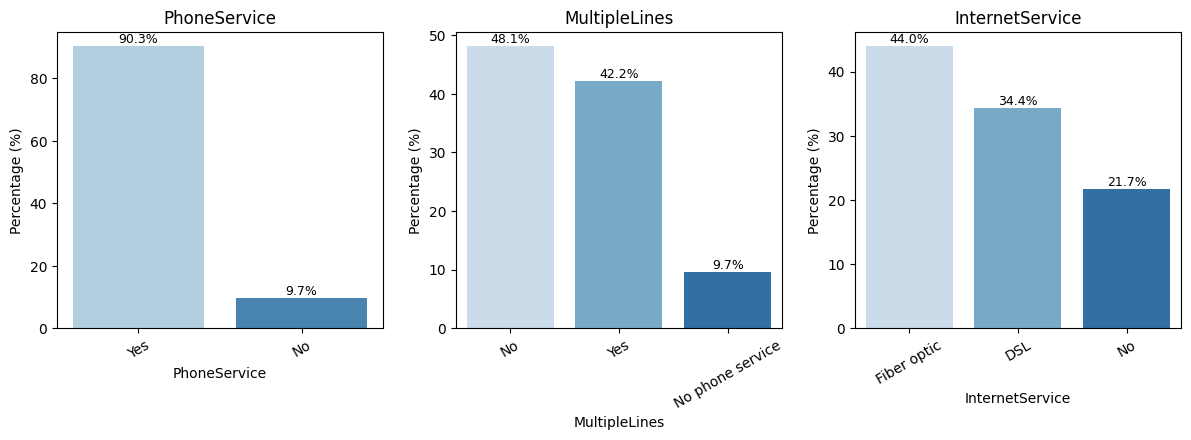

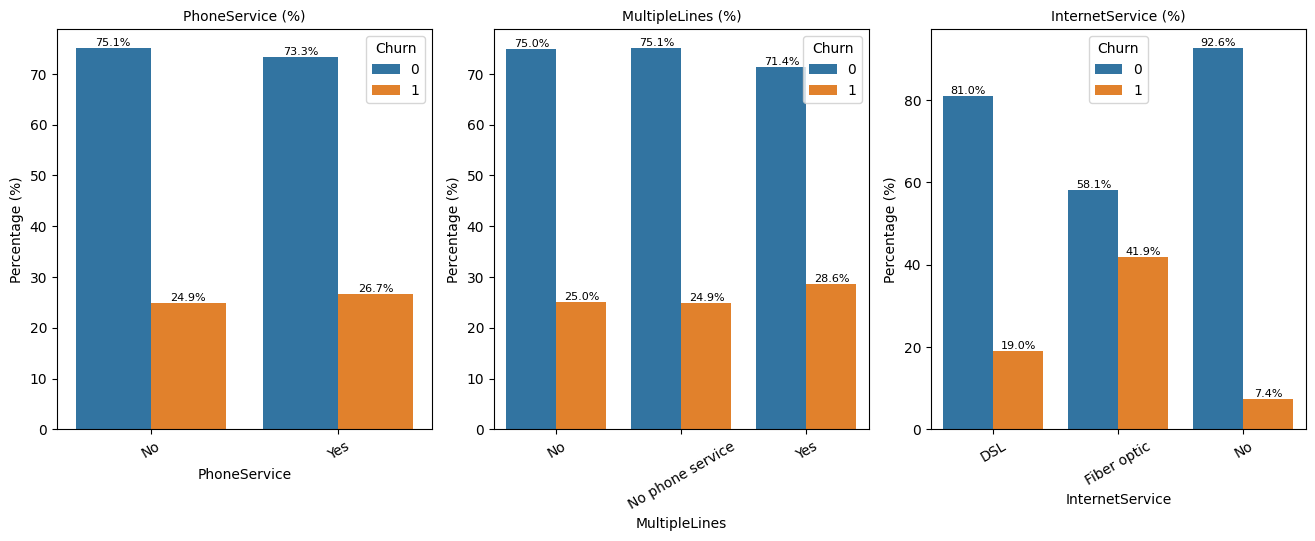

In [100]:
plt.figure(figsize=(16, 20))

for i, col in enumerate(phone_int_service_cols, 1):
    plt.subplot(5, 4, i)

    # hitung persentase
    pct = df[col].value_counts(normalize=True) * 100

    ax = sns.barplot(x=pct.index, y=pct.values, palette="Blues")

    # label persen
    for p in ax.patches:
        ax.annotate(
            f"{p.get_height():.1f}%",
            (p.get_x() + p.get_width()/2, p.get_height()),
            ha="center", va="bottom", fontsize=9
        )

    plt.title(col)
    plt.ylabel("Percentage (%)")
    plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

# Plot Phone Internet Service vs Churn Rate

plt.figure(figsize=(22, 20))
rows, cols = 4, 5

for i, col in enumerate(phone_int_service_cols, 1):
    plt.subplot(rows, cols, i)

    # Hitung persentase per kategori & churn
    percent_df = (
        df.groupby([col, "Churn"], as_index=False)
          .size()
    )

    percent_df["percentage"] = (
        percent_df
        .groupby(col)["size"]
        .transform(lambda x: 100 * x / x.sum())
    )

    ax = sns.barplot(
        data=percent_df,
        x=col,
        y="percentage",
        hue="Churn"
    )

    # Tambahkan label percentage di atas bar
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.1f%%",
            label_type="edge",
            fontsize=8
        )

    plt.title(f"{col} (%)", fontsize=10)
    plt.ylabel("Percentage (%)")
    plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

#### ***4.3.1 Analisa plot kategorikal phone internet service kolom***

- Chart Phone Service: Pelanggan yang mempunyai PhoneService cenderung lebih sering churn.
- Chart MultipleLines: Distribusi antara pelanggan yang mempunyai multipleLines atau tidak cukup seimbang meskipun yang tidak mempunyai multipleLines cenderung sedikit lebih tinggi churn ratenya.
- Chart Internet Service: Pelanggan yang mempunyai service Fiber Optic cenderung lebih tinggi churn ratenya dibanding yang mempunyai service DSL ataupun tidak mempunyai Internet Service.

#### ***4.3.2 Analisa Phone Internet Service by Churn Rate***

- Dari chart phone service dapat diambil kesimpulan pelanggan yang mempunyai phone service cenderung memiliki churn rate lebih tinggi dibanding yang tidak mempunyai phone service. Ini mungkin dirasakan mempunyai phone service dirasa tidak perlu di masa masyarakat pada umumnya menggunakan handphone.
- Dapat dilihat dari chart MultipleLines tidak ada perbedaan jauh untuk churn rate antara gender pelanggan ataupun pelanggan yang memiliki/tidak memiliki beberapa line telpon.
- Melainkan pelanggan yang mempunyai Fiber Optic lebih tinggi churn ratenya dibanding yang hanya mmepunyai DSL ataupun tidak ada internet service. Ini dimungkinkan Fiber Optic memakan biaya yang lebih tinggi dibanding DSL.

### ***4.4 Analisa Online Support Kolom***

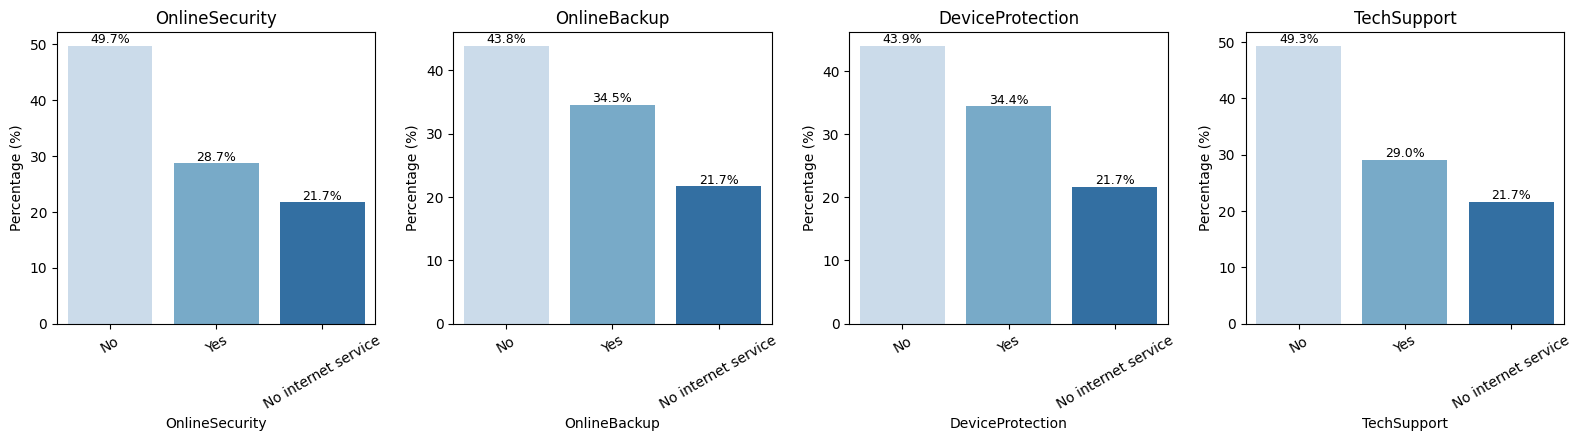

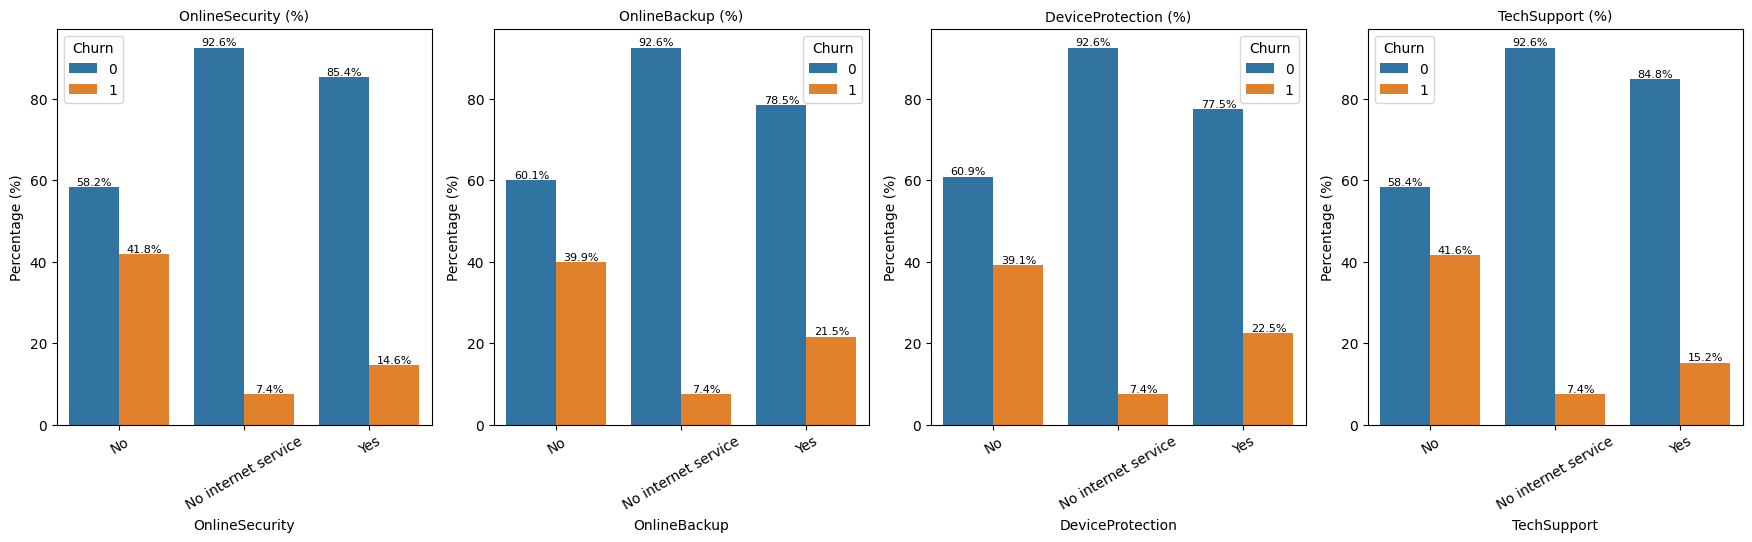

In [101]:
plt.figure(figsize=(16, 20))

for i, col in enumerate(online_support_cols, 1):
    plt.subplot(5, 4, i)

    # hitung persentase
    pct = df[col].value_counts(normalize=True) * 100

    ax = sns.barplot(x=pct.index, y=pct.values, palette="Blues")

    # label persen
    for p in ax.patches:
        ax.annotate(
            f"{p.get_height():.1f}%",
            (p.get_x() + p.get_width()/2, p.get_height()),
            ha="center", va="bottom", fontsize=9
        )

    plt.title(col)
    plt.ylabel("Percentage (%)")
    plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

# Plot Online Support Kolom vs Churn Rate

plt.figure(figsize=(22, 20))
rows, cols = 4, 5

for i, col in enumerate(online_support_cols, 1):
    plt.subplot(rows, cols, i)

    # Hitung persentase per kategori & churn
    percent_df = (
        df.groupby([col, "Churn"], as_index=False)
          .size()
    )

    percent_df["percentage"] = (
        percent_df
        .groupby(col)["size"]
        .transform(lambda x: 100 * x / x.sum())
    )

    ax = sns.barplot(
        data=percent_df,
        x=col,
        y="percentage",
        hue="Churn"
    )

    # Tambahkan label percentage di atas bar
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.1f%%",
            label_type="edge",
            fontsize=8
        )

    plt.title(f"{col} (%)", fontsize=10)
    plt.ylabel("Percentage (%)")
    plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

#### ***4.4.1 Analisa Plot Kategorikal Online Tech Support Service kolom***

- Chart Internet Service lainnya eg. Online Security, Online Backup, Device Protection, Tech Support: semua chart tersebut mempunyai karakterikstik yang serupa dalam arti - Pelanggan yang tidak mempunyai service-service tersebut cenderung lebih tinggi churn ratenya. Dapat disimpulkan bahwa pelanggan dengan tambahan internet service (atau add-on) cenderung menyebabkan retensi lebih tinggi.

#### ***4.4.2 Analisa Online Support Kolom by Churn Rate***

- Dari kedua chart tersebut (Online Security & Online Backup) dapat diambil kesimpulan bahwa pelanggan mempunyai kedua service tersebut memiliki churn rate yang lebih rendah dibanding yang tidak mempunyai kedua service tersebut. 
- Melainkan pelanggan yang mempunyai Fiber Optic lebih tinggi churn ratenya dibanding yang hanya mmepunyai DSL ataupun tidak ada internet service. Ini dimungkinkan Fiber Optic memakan biaya yang lebih tinggi dibanding DSL.
- Dari chart TechSupport dapat disimpulkan bahwa pelanggan yang mempunyai langganan Tech Support cenderung memiliki churn rate lebih rendah dibanding pelanggan yang tidak mempunyai service tersebut.


### ***4.5 Analisa Streaming Kolom***

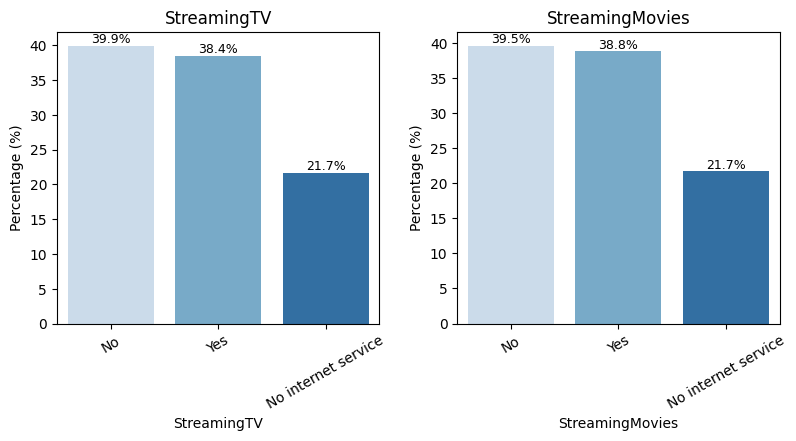

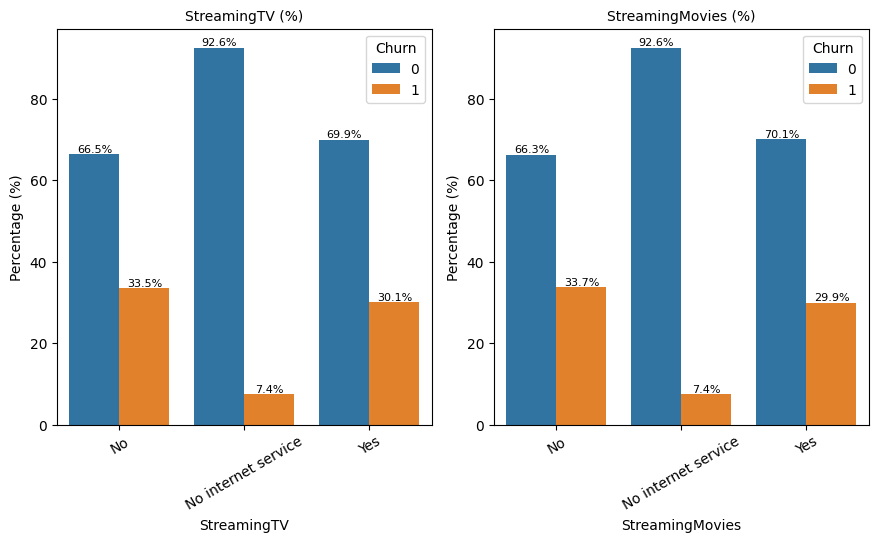

In [102]:
plt.figure(figsize=(16, 20))

for i, col in enumerate(streaming_cols, 1):
    plt.subplot(5, 4, i)

    # hitung persentase
    pct = df[col].value_counts(normalize=True) * 100

    ax = sns.barplot(x=pct.index, y=pct.values, palette="Blues")

    # label persen
    for p in ax.patches:
        ax.annotate(
            f"{p.get_height():.1f}%",
            (p.get_x() + p.get_width()/2, p.get_height()),
            ha="center", va="bottom", fontsize=9
        )

    plt.title(col)
    plt.ylabel("Percentage (%)")
    plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

# Plot Streaming Kolom vs Churn Rate

plt.figure(figsize=(22, 20))
rows, cols = 4, 5

for i, col in enumerate(streaming_cols, 1):
    plt.subplot(rows, cols, i)

    # Hitung persentase per kategori & churn
    percent_df = (
        df.groupby([col, "Churn"], as_index=False)
          .size()
    )

    percent_df["percentage"] = (
        percent_df
        .groupby(col)["size"]
        .transform(lambda x: 100 * x / x.sum())
    )

    ax = sns.barplot(
        data=percent_df,
        x=col,
        y="percentage",
        hue="Churn"
    )

    # Tambahkan label percentage di atas bar
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.1f%%",
            label_type="edge",
            fontsize=8
        )

    plt.title(f"{col} (%)", fontsize=10)
    plt.ylabel("Percentage (%)")
    plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

#### ***4.5.1 Analisa Plot Kategorikal Streaming Kolom***

- Chart Streaming TV dan Streaming Movies: kedua chart tersebut mempunyai kemiripan dalam arti - distribusi antara yang mempunyai streaming service atau tidak serupa dan tidak berpengaruh banyak terhadapt churn rate.

#### ***4.5.2 Analisa Streaming Service by Churn Rate***

- Dapat dilihat dari kedua chart tidak ada perbedaan yang berarti untuk churn rate antara pelanggan yang mempunyai Streaming TV ataupun Streaming Movies.

### ***4.6 Analisa Finance Kolom***

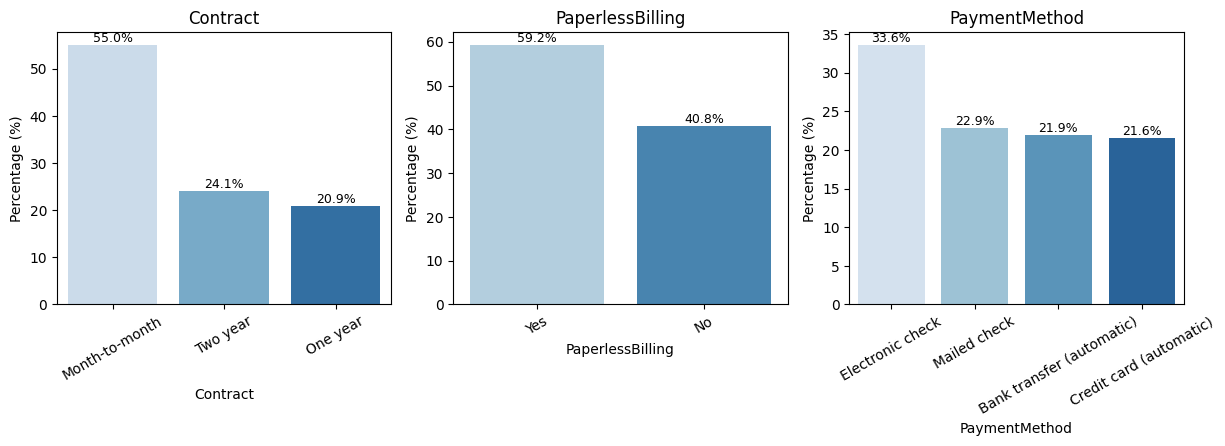

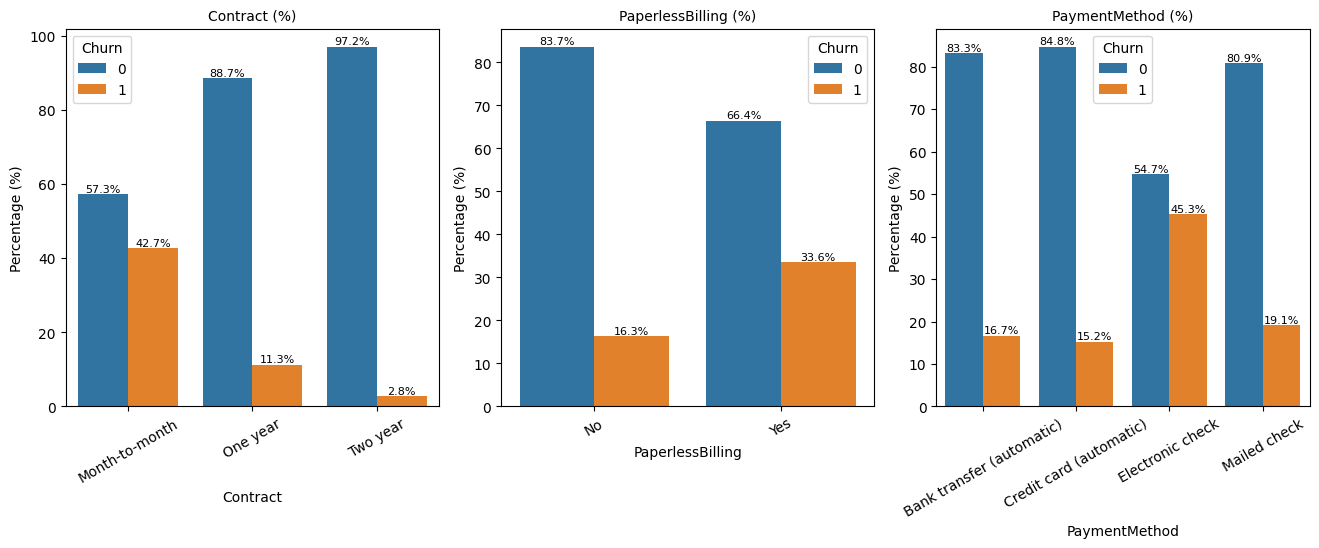

In [103]:
plt.figure(figsize=(16, 20))

for i, col in enumerate(finance_cols, 1):
    plt.subplot(5, 4, i)

    # hitung persentase
    pct = df[col].value_counts(normalize=True) * 100

    ax = sns.barplot(x=pct.index, y=pct.values, palette="Blues")

    # label persen
    for p in ax.patches:
        ax.annotate(
            f"{p.get_height():.1f}%",
            (p.get_x() + p.get_width()/2, p.get_height()),
            ha="center", va="bottom", fontsize=9
        )

    plt.title(col)
    plt.ylabel("Percentage (%)")
    plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

plt.figure(figsize=(22, 20))
rows, cols = 4, 5


# Finance Kolom by Churn Rate

for i, col in enumerate(finance_cols, 1):
    plt.subplot(rows, cols, i)

    # Hitung persentase per kategori & churn
    percent_df = (
        df.groupby([col, "Churn"], as_index=False)
          .size()
    )

    percent_df["percentage"] = (
        percent_df
        .groupby(col)["size"]
        .transform(lambda x: 100 * x / x.sum())
    )

    ax = sns.barplot(
        data=percent_df,
        x=col,
        y="percentage",
        hue="Churn"
    )

    # Tambahkan label percentage di atas bar
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%.1f%%",
            label_type="edge",
            fontsize=8
        )

    plt.title(f"{col} (%)", fontsize=10)
    plt.ylabel("Percentage (%)")
    plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

#### ***4.6.1 Analisa Plot Kategorikal Finance Kolom***

- Chart Contract: Pelanggan dengan month to month contract (kontrak bulanan) cenderung memiliki churn rate yang jauh lebih tinggi dari pelanggan dengan kontrak one year (tahunan) atau two year (dua tahunan).
- Chart Paperless Billing: Pelanggan dengan paperless billing memiliki churn lebih tinggi.
- Chart Payment Method: Pelanggan yang menggunakan pembayaran Electronic Check memiliki churn rate yang lebih tinggi dibanding metode pembayaran yang lain seperti Mailed Check, Bank Transfer atau Credit Card.

#### ***4.6.2 Analisa Finance Kolom by Churn Rate***
- Melainkan pelangggan yang tipe kontraknya berupa month to month (tagihan bulanan) cenderung memiliki churnrate yang jauh lebih tinggi dibanding kontrak tahunan atau kontrak per 2 tahunan.
- Dari chart Paperless Billing dapat dilihat pelanggan yang menggunakan paperless billing cenderung memiliki churn rate dibanding yang menggunakan tagihan kertas biasa.
- Dari chart payment method dapat diambil kesimpulan pelanggan yang menggunakan pembayaran electronic check memiliki churn rate yang jauh lebih tinggi dibanding metode pembayaran yang lain eg. mailed check, bank transfer dan credit card.

Feature kategorikal yang berpotensi mempunyai importance:
- Contract
- PaymentMethod
- InternetService
- TechSupport / OnlineSecurity
- PaperlessBilling
- Dependents / Partner

#### ***4.6.2 Analisa Numerikal Kolom dengan Churn Rate = 1 (Yes)***

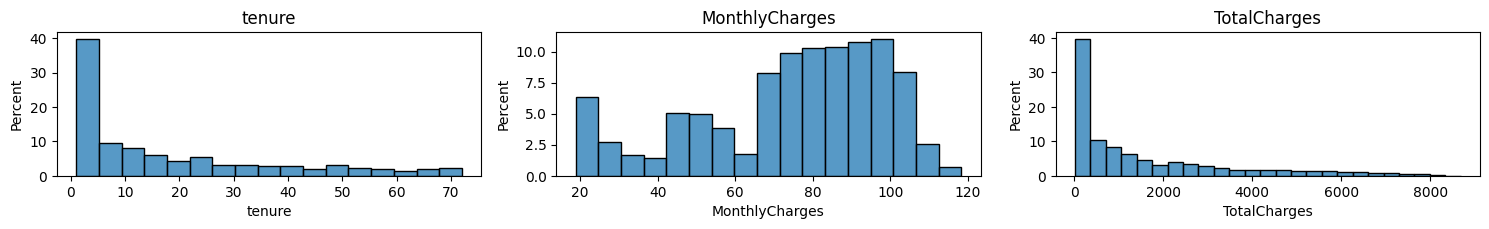

In [104]:
df_churn_yes = df[df["Churn"] == 1]

plotnumber = 1
plt.figure(figsize=(15, 6))

for kolom in numeric_cols:
    plt.subplot(3, 3, plotnumber)
    sns.histplot(
        data=df_churn_yes,
        x=kolom,
        stat="percent" 
    )
    plt.title(kolom)
    plt.tight_layout()
    plotnumber += 1

plt.show()

### ***4.7 Analisa Plot Numerikal***

- Chart Tenure: Dapat diambil kesimpulan pelanggan relatif baru (tenure dibawah 6 bulan) mempunyai churn rate yang sangat tinggi dibanding pelanggan diatas 6 bulan sampai hampir 70 bulan.
- Chart Monthly Charges (tagihan berjalan): Dapat dilihat bahwa pelanggan yang memiliki tagihan bulanan diatas $70-110 memiliki kecenderungan tinggi untuk churn. Ini juga dibuktikan dengan pelanggan yang memiliki banyaknya add-on internet service memiliki churn rate yang tinggi.
- Chart Total Charges (tagihan yang tercetak): Dapat dilihat bahwa TotalCharges (tagihan tercetak) mendekati $0 memiliki churn rate yang sangat tinggi (Artinya pelanggan belum berlanggan 1 bulan sudah churn). 

### ***4.8 Analisa Numerikal Kolom dalam BoxPlot***

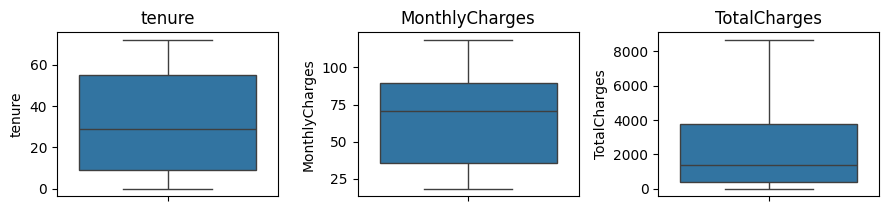

In [105]:
plt.figure(figsize=(12, 4))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(2, 4, i)
    sns.boxplot(y=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

### ***4.8.1 Analisa Boxplot***

- Analisa lebih dalam akan dilakukan di bagian Machine Learning

### ***4.9 Correlation Heat Map***

In [106]:
numeric_cols_corr = numeric_cols.corr(method='spearman', numeric_only=True) 
numeric_cols_corr

,tenure,MonthlyCharges,TotalCharges
tenure,1.000000,0.276417,0.889696
MonthlyCharges,0.276417,1.000000,0.638028
TotalCharges,0.889696,0.638028,1.000000


Pakai method='spearman' karena kolom data rata-rata tidak ter-Distribusi Normal

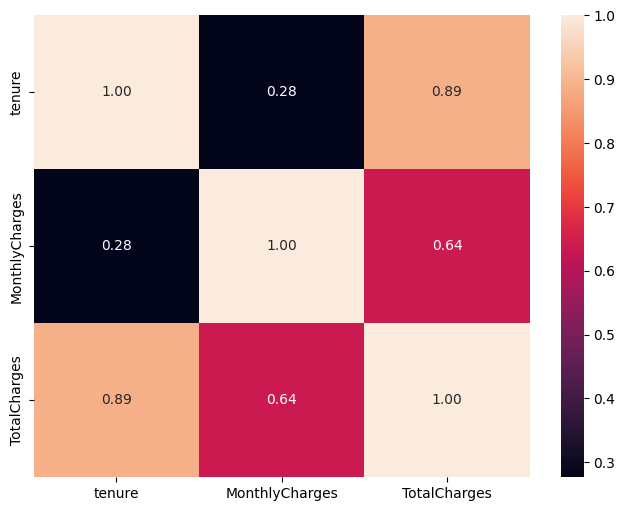

In [107]:
plt.figure(figsize=(8,6))
sns.heatmap(numeric_cols_corr, annot=True, fmt='.2f')
plt.show()

#### ***4.9.1 Analisa Korelasi HeatMap***

- Tenure vs TotalCharges: Memiliki korelasi yang sangat kuat 0.89 - Total tagihan berbanding linear dengan Tenure. Ini menandakan semakin tingginya TotalCharges semakin tingginya juga churn rate.
- Tenure vs MonthlyCharges: Memiliki korelasi yang sedikit 0.28 - Tagihan bulanan berbanding linear dengan Tenure. Ini menandakan semakin tingginya MonthlyCharges semakin tingginya juga churn rate.

# ***5. Machine Learning***

### ***5.1 Load Data and Data Checking***

In [108]:
df.shape

(7043, 21)

In [109]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   object 
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


### ***5.2 Pisahkan Features dan Target (Data Spliting)***

In [110]:
# Define X y
X = df.drop(columns=['Churn','customerID']) # Features
y = df['Churn'] # Target

In [111]:
y.nunique()

2

In [112]:
y.value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [113]:
X.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges'],
      dtype='object')

### ***5.3 Train-test Split***

In [114]:
# menggunakan Stratify agar data test dan data train proporsinya tetap sama
X_train, X_test, y_train, y_test = train_test_split (X, y, test_size=0.2, random_state=42, stratify=y)

### ***5.4 Data Preparation***

In [115]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [116]:
X.nunique()

gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
dtype: int64

In [117]:
categorical_cols

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod'],
      dtype='object')

In [118]:
X.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges'],
      dtype='object')

### ***5.5 Penggunaan Boxplot pada kolom numerikal***

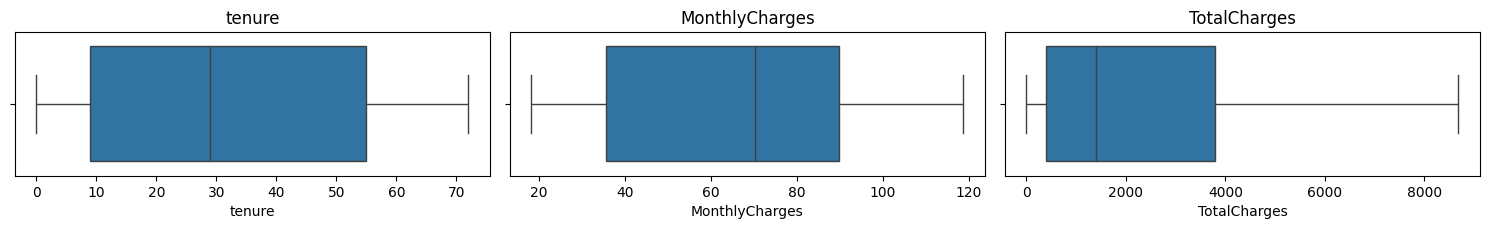

In [119]:
plotnumber = 1
plt.figure(figsize=(15,6))
for kolom in numeric_cols:
    plt.subplot(3,3,plotnumber)
    sns.boxplot(data=df, x=kolom)
    plt.title(kolom)
    plt.tight_layout()
    plotnumber +=1

### Analisa Boxplot:

- Tidak ada outlier yang berarti pada tenure.
- MonthlyCharges terdapat sedikit outliers sampai nilai mendekati $120.
- TotalCharges terdapat outliers yang cukup berarti. Boxplot terlihat sangat Right Skewed.
- RobustScaler akan dipakai untuk Scaling Numerikal Feature. RobustScaler menggunakan median & IQR (Interquartile Range rentang Q3 dan Q1) dan kebal terhadap outlier, skewed data dan distribusi data tidak normal.
- Penggunaan StandardScaler tidak dipakai karena formula tergantung pada mean dan std deviation yang memungkinkan feature tidak stabil. Model linear sangat sensitif terhadap hal ini. Logistic Regression bisa memberi bobot salah pada fitur dengan distribusi berat sebelah.

### ***5.5 Data Preprocessing***

Pada tahap ini kita akan melakukan feature encoding untuk data-data kategorikal yang kita miliki dan numerikal scaling untuk data-data numerikal.

Penggunaan OneHotEncoder karena data kategorikal ini sebagian besar mempunyai value 0/1, tidak bersifat ordinal, dan jumlah unique data yang sedikit. Bila variasi value yang cukup besar tidak disarankan menggunakan OneHotEncoder.

Encoding:
- OneHotEncoder: gender, SeniorCitizen,  Partner, Dependents, PhoneService, MultipleLines , InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling, PaymentMethod, MonthlyCharges (OneHotEncoder untuk data kategorikal).


Penggunaan RobustScaler karena dalam beberapa kolom numerikal terlihat data skewed dan ada beberapa outliers. Model RobustScaler lebih tahan terhadap outliers dibanding StandardScaler.

Scaling:
- RobustScaler: tenure, MonthlyCharges, TotalCharges (Memakai RobustScaler karena dalam beberapa kolom tesebut terlihat adanya data skewed dan outliers, jadi tidak menggunakan StandardScaler).

### ***5.5.1 Preprocessing Pipeline***

In [120]:
preprocessor = ColumnTransformer([
    ('kategorikal', OneHotEncoder(drop='first'),['gender','SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 
        'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']),
    ('numerikal', RobustScaler(), ['tenure','MonthlyCharges','TotalCharges'])
], remainder = 'passthrough')

preprocessor

ColumnTransformer(remainder='passthrough',
                  transformers=[('kategorikal', OneHotEncoder(drop='first'),
                                 ['gender', 'SeniorCitizen', 'Partner',
                                  'Dependents', 'PhoneService', 'MultipleLines',
                                  'InternetService', 'OnlineSecurity',
                                  'OnlineBackup', 'DeviceProtection',
                                  'TechSupport', 'StreamingTV',
                                  'StreamingMovies', 'Contract',
                                  'PaperlessBilling', 'PaymentMethod']),
                                ('numerikal', RobustScaler(),
                                 ['tenure', 'MonthlyCharges', 'TotalCharges'])])

### ***5.6 Summary Step untuk Tuning Model***

- Confusion Matrix Before Tuning (semua model, test set) 

- Cross Validation (CV) selection (F2 mean) -> pilih best model

- Confusion Matrix After CV (best model, default threshold)

- GridSearchCV tuning (hanya best model)

- Confusion Matrix After Tuning (best tuned model, default threshold)

- Threshold tuning F2 (pakai best tuned model)

- Confusion Matrix After Threshold (best threshold)

### ***5.6.1 Define Model to Compare (Basic ML Algorithm)***

In [121]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42), # Model dasar yang interpretable dan linear.
    'KNN': KNeighborsClassifier(), # Model yang mengklasifikasikan berdarsarkan tetangga terdekat pada feature.
    'Decision Tree': DecisionTreeClassifier(random_state=42), # Model pohon yang membagi data berdasarkan fitur penting.
    'Random Forest': RandomForestClassifier(random_state=42), # Model kumpulan ensemble banyak decision tree.
    'Gradient Boosting': GradientBoostingClassifier(random_state=42), # Membangun model secara bertahap (boosting), setiap pohon memperbaiki dari kesalahan pohon sebelumnya.
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss'), # Versi boosting yang lebih cepat & efisien dari Gradient Boosting
    'LightGBM': LGBMClassifier(random_state=42) # Model algoritma boosting ringan dan sangat cepat, bagus untuk dataset besar (Menggunakan historgram-based splitting)
}

### ***5.6.2 Confusion Matrix Before Tuning (Semua Model, Default Threshold)***

=== Confusion Matrix Sebelum Tuning ===
[LightGBM] [Info] Number of positive: 1495, number of negative: 4139
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001627 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 637
[LightGBM] [Info] Number of data points in the train set: 5634, number of used features: 30
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.265353 -> initscore=-1.018328
[LightGBM] [Info] Start training from score -1.018328


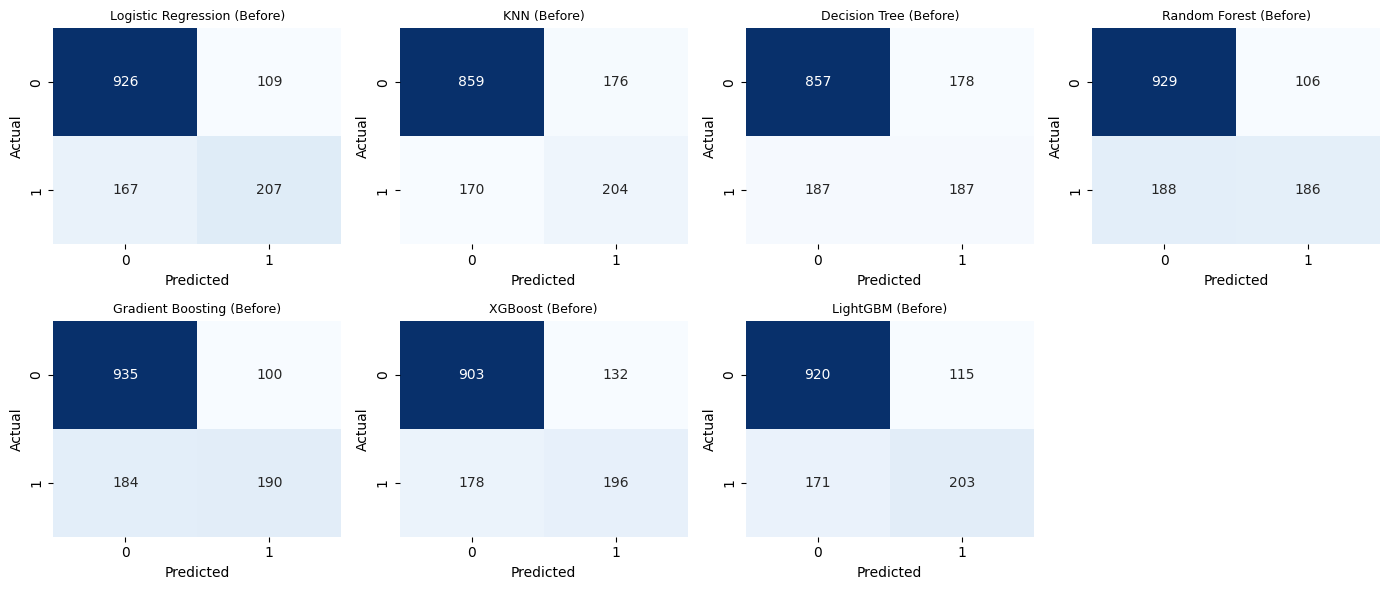

In [122]:
print("=== Confusion Matrix Sebelum Tuning ===")
plt.figure(figsize=(14, 6))

for i, (name, model) in enumerate(models.items()):
    pipe = Pipeline([("preprocessor", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)
    
    plt.subplot(2, (len(models)+1)//2, i+1)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f"{name} (Before)", fontsize=9)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    
plt.tight_layout()
plt.show()

Analisa Confusion Matrix Sebelum Tuning:
- Terlihat Angka FN 167 terendah didapat dari model Logistic Regression. Ini mengindikasikan FN rendah dan banyak churn yang tidak lolos.

### ***5.6.3 Cross Validation (CV) selection (F2 mean) -> pilih best model***

In [123]:
# CV Selection melalui F2 Mean

# Stratified supaya proporsi churn seimbang di tiap fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# F2 Scorer
f2_scorer = make_scorer(fbeta_score, beta=2)

scoring = {
    # "accuracy": "accuracy",
    # "precision": "precision",
    # "recall": "recall",
    # "f1": "f1",
    "f2": f2_scorer,             
    # "roc_auc": "roc_auc",
    # "pr_auc": "average_precision"
}


cv_results = []

for name, model in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

    cv_results.append({
        "model": name,
        "f2_mean": np.mean(scores["test_f2"]),
        "f2_std": np.std(scores["test_f2"])
    })

cv_df = pd.DataFrame(cv_results).sort_values(by="f2_mean", ascending=False)

print("\n=== Cross Validation Results (sorted by F2) ===")
display(cv_df)

best_model_name = cv_df.iloc[0]["model"]
best_model = models[best_model_name]
best_pipe = Pipeline([("preprocess", preprocessor), ("model", models[best_model_name])])
best_pipe.fit(X_train, y_train)

print("\nBest model by CV (F2):", best_model_name)


=== Cross Validation Results (sorted by F2) ===


,model,f2_mean,f2_std
0,Logistic Regression,0.562430,0.037820
1,KNN,0.545051,0.005660
4,Gradient Boosting,0.540537,0.014078
6,LightGBM,0.540150,0.021204
5,XGBoost,0.524712,0.016946
3,Random Forest,0.497350,0.026429
2,Decision Tree,0.494548,0.024847



Best model by CV (F2): Logistic Regression


Analisa F2_mean dan F2_std score:
- Model terbaik denga F2_Mean Score adalah Logistic Regression.
- Mesikpun f2_std untuk Logistic Regression adalah yang tertinggi, tetapi tetap relatif kecil dibanding model-model lainnya. Ini menandakan Logistic Regresion ber-performa baik dan model yang cukup stabil dan konsisten di seluruh fold cross-validation.

### ***5.6.4 Confusion Matrix After CV (best model, default threshold)***


=== Confusion Matrix Sesudah CV (Best Model, default) ===


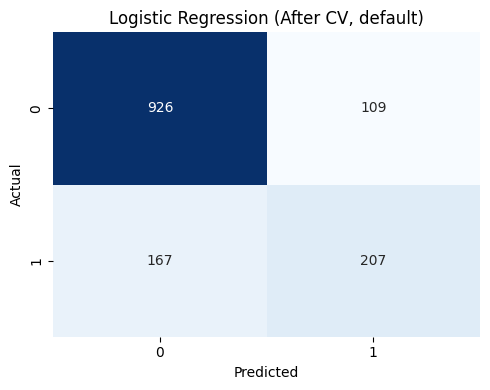

In [124]:
best_pipe = Pipeline([("preprocessor", preprocessor), ("model", models[best_model_name])])
best_pipe.fit(X_train, y_train)

y_pred_best = best_pipe.predict(X_test)
cm_best = confusion_matrix(y_test, y_pred_best)

print("\n=== Confusion Matrix Sesudah CV (Best Model, default) ===")
plt.figure(figsize=(5, 4))
sns.heatmap(cm_best, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title(f"{best_model_name} (After CV, default)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

Analisa hasil consfusion matrix menunjukkan performa best model yang dipilih CV masih dengan parameter default. Sehingga hasil FN masih sama di angka 167.

### ***5.6.5 GridSearchCV Tuning (hanya best model)***

In [125]:
param_grids = {
    'Logistic Regression': {
        'model__C': [0.01, 0.1, 1, 10],  # Invers regularization strength, 0.001-0.01 regulasi kuat, 0.1-1 regulasi sedang, 10 regulasi lemah
        'model__solver': ['liblinear', 'lbfgs'] # Algoritma Optimasi, liblinear: dataset kecil-menengah, lbfgs dataset besar, fitur banyak.
    },
    'KNN': {
        'model__n_neighbors': [3, 5, 7, 9], 
        # n_neighbors 3 - Nilai kecil - model kompleks/sensitif, 5-9 - Nilai Sedang - model seimbang. 
        # Akan dibandingkan semua skor dan pilih k terbaik.
        'model__weights': ['uniform', 'distance']
        # parameter weights di KNN, 'uniform' semua tetangga dihitung dengan pengaruh yang sama besar, 
        # 'distance' tetangga yang lebih dekat memiliki bobot lebih besar
    },
    'Decision Tree': {
        'model__max_depth': [3, 5, 10, None], # Melihat kedalaman pohon dari 3 level sampai ke tingkat None (tidak terbatas), idealnya di level 5.
        'model__min_samples_split': [2, 5, 10] 
        # menentukan berapa banyak data minimum yang harus dimiliki sebuah node sebelum dipecah lagi. 
        # Biasanya di nilai 5 jadi tidak resiko overfit atau underfit.
    },
    'Random Forest': {
        'model__n_estimators': [50, 100], 
        # jumlah pohon keputusan (decision trees), nilai 50 kecil - cepat dilatih tapi kurang stabil.
        # Sedang (100-200) - umum hasil terbaik, cukup stabil
        # Besar (>500) - Akurasi bisa sedikit naik tapi waktu training lama
        'model__max_depth': [10, 20, None],
        # menandakan maksimum tiap pohon, 10 - pohon 10 level mencegah overfit, 20 - lebih dalam - resiko overfit meningkat, None - tanpa batas - bisa overfit
        'model__min_samples_split': [2, 10]
        # 2 - default - model lebih flexibel, bisa overfit, 10 - minimal harus ada 10 data untuk split, model lebih sederhana underfit
    },
    'Gradient Boosting': {
        'model__learning_rate': [0.05, 0.1],
        # kontribusi tiap pohon baru terhadap model keseluruhan, kecil (0.01-0.05) model lebih stabil, resiko overfit kecil
        # sedang (0.1) hasil terbaik antara kecepatan dan akurasi
        # besar (>0.3) model lebih cepat belajar, tapi bisa overfit
        'model__n_estimators': [100, 200],
        # pohon kecil (weak learners) yang dibangun secara beruturan, 100 - cepat dilatih, cukup akurat, 200 - lebih banyak pohon tapi butuh waktu lebih lama, 
        # >500 bisa mulaioverfit jika learning rate tidak kecil
        'model__max_depth': [3, 5]
        # Kedalaman setiap pohon kecil di dalam boosting
        # 3 - default, sederhana, cepat dan stabil, 5 - pohon lebih dalam - bisa menangkap fitur yang lebih kompleks, >7 - jarang perlu bisa overfit
    },
    'XGBoost': {
        'model__learning_rate': [0.05, 0.1],
        # seberapa cepat model belajar, 0.05 - pelan tapi stabil, aman dari overfit, 0.1 - efek sedang - cepat belajar, sering jadi default terbaik, 
        # >0.3 - terlalu cepat, model bisa overfit
        'model__max_depth': [3, 5],
        # seberapa dalam tiap pohon
        # nilai 3 - dangkal - pohon sederhana, model general, risiko underfit kecil, 5 - lebih dalam - bisa tangkap pola kompleks, 
        # >7 - sangat dalam - biasanya overfit, jarang perlu
        'model__colsample_bytree': [0.8, 1.0]
        # proporsi fitur yang diambil tiap pohon
        # 1.0 - gunakan semua fitur, akurasi tinggi tapi bisa overfit, 0.8 - gunakan 80% dari fitur, lebih variasi, mengurangi overfitting, <0.8 kurang fitur, bisa underfit
    },
    'LightGBM': {
        'model__learning_rate': [0.05, 0.1],
        # seberapa cepat model belajar, 0.05 - pelan tapi stabil, aman dari overfit, 0.1 - efek sedang - cepat belajar, sering jadi default terbaik, 
        # >0.3 - terlalu cepat, model bisa overfit
        'model__num_leaves': [31, 50],
        # Jumlah maksimum daun per pohon
        # 31 - default - pohon sederhana, 50 - lebih banyak daun - bisa tangkap pola rumit tapi resiko overfit, >100 - sangat kompleks, bisa overfit
        'model__max_depth': [-1, 5, 10]
        # seberapa dalam tiap pohon
        # nilai 3 - dangkal - pohon sederhana, model general, risiko underfit kecil, 5 - lebih dalam - bisa tangkap pola kompleks, 
        # >7 - sangat dalam - biasanya overfit, jarang perlu
        
    }
}

# GridsearchCV Tuning
grid_pipe = Pipeline([("preprocessor", preprocessor), ("model", best_model)])

grid = GridSearchCV(
    estimator=grid_pipe,
    param_grid=param_grids[best_model_name],
    scoring=f2_scorer,
    cv=cv,
    n_jobs=-1
)

grid.fit(X_train, y_train)
best_tuned_pipe = grid.best_estimator_

print("\n=== GridSearchCV Result ===")
print("Best params:", grid.best_params_)
print("Best CV F2 :", round(grid.best_score_, 4))


=== GridSearchCV Result ===
Best params: {'model__C': 10, 'model__solver': 'liblinear'}
Best CV F2 : 0.5648


Analisa dari hasil diatas adalah dari Tuning yang dilakukan untuk model terbaik saja. Scoring tetap menggunakan F2 Score untuk menekan FN.

### ***5.6.6 Confusion Matrix After Tuning (best tuned model, default threshold)***


=== Confusion Matrix Sesudah Tuning (Default) ===


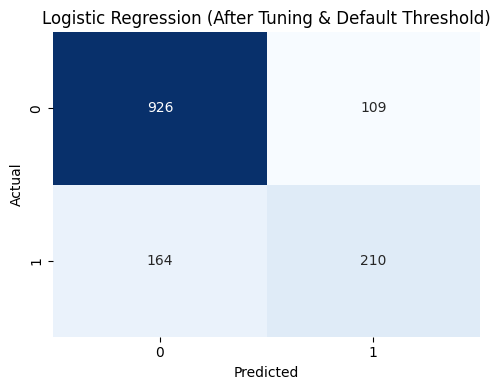

In [126]:
y_pred_tuned_default = best_tuned_pipe.predict(X_test)
cm_tuned_default = confusion_matrix(y_test, y_pred_tuned_default)

print("\n=== Confusion Matrix Sesudah Tuning (Default) ===")
plt.figure(figsize=(5, 4))
sns.heatmap(cm_tuned_default, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title(f"{best_model_name} (After Tuning & Default Threshold)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

Hasil evaluasi model hasil tuning dengan False Negative: 164 tetapi hasil tersebut masih dengan threshold default 0.5

### ***5.6.7 Threshold tuning F2 (pakai best tuned model)***

In [127]:
train_proba = best_pipe.predict_proba(X_train)[:, 1]
thresholds = np.arange(0.10, 0.90, 0.05)

best_t, best_f2 = None, -1
for t in thresholds:
    pred_t = (train_proba >= t).astype(int)
    f2 = fbeta_score(y_train, pred_t, beta=2, zero_division=0)
    if f2 > best_f2:
        best_f2 = f2
        best_t = t

print("\nBest threshold for F2 (TRAIN):", round(best_t, 2), "| Best F2:", round(best_f2, 4))


Best threshold for F2 (TRAIN): 0.15 | Best F2: 0.7536


Hasil Tuning diatas mendapatkan Best Threshold di angka 0.15 dengan Best F2 Score: 0.7536. Ini sudah merupakan peningkatan dari Score sebelumnya di angka 0.562430.

### ***5.6.8 CONFUSION MATRIX AFTER Tuning dan Threshold (Diterapkan pada Test Set)***


=== Confusion Matrix Sesudah Threshold (Best Tuned) ===


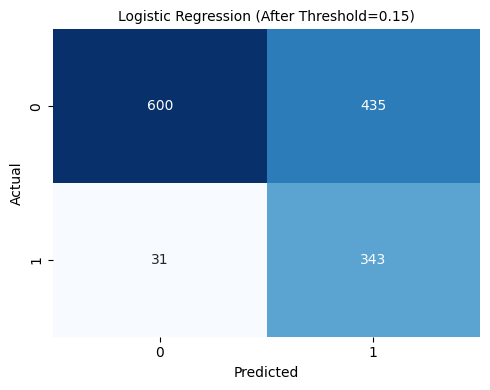

In [128]:
test_proba = best_tuned_pipe.predict_proba(X_test)[:, 1]
y_pred_after_threshold = (test_proba >= best_t).astype(int)
cm_after_threshold = confusion_matrix(y_test, y_pred_after_threshold)

print("\n=== Confusion Matrix Sesudah Threshold (Best Tuned) ===")
plt.figure(figsize=(5, 4))
sns.heatmap(cm_after_threshold, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title(f"{best_model_name} (After Threshold={best_t:.2f})", fontsize=10)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

Hasil Confusion Matrix memperlihatkan setelah Parameter Tuning dan Threshold Tuning angka False Negative (FN) turun ke angka 31 dari sebelumnya diangkat 164. Pada bagian kesimpulan dan rekomendasi akan di berikan cost benefit analysis dari semua proses tuning dan threshold pada model Logistic Regression.

### ***5.7 Feature Importance***

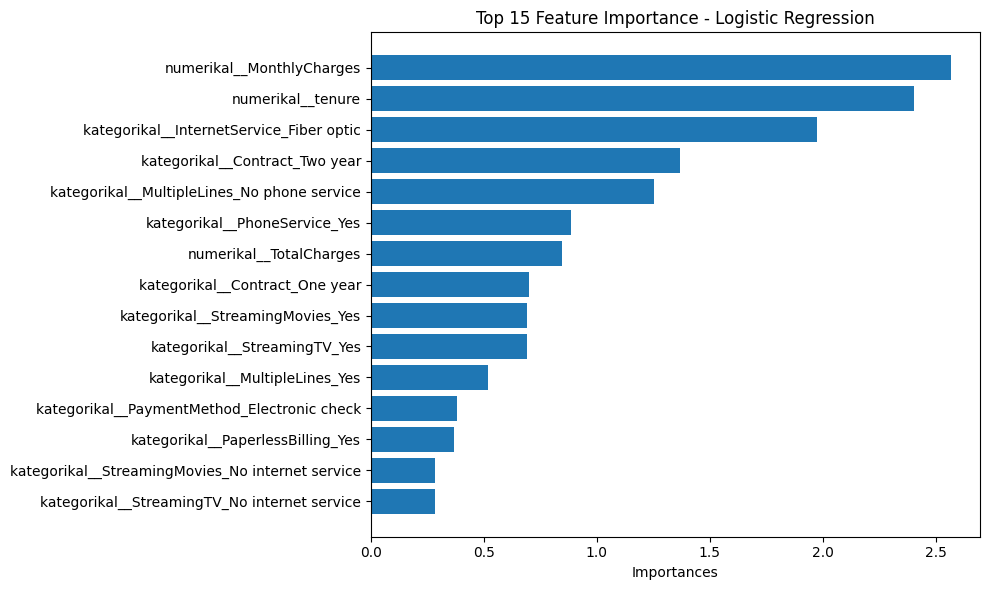

In [129]:
# Model terbaik
best_model = best_tuned_pipe.named_steps["model"]

# Feature names dari preprocessor
feature_names = best_tuned_pipe.named_steps["preprocessor"].get_feature_names_out()

importances = np.abs(best_model.coef_[0])

# Top 15 Importances
indices = np.argsort(importances)[::-1][:15]

plt.figure(figsize=(10, 6))
plt.barh(np.array(feature_names)[indices][::-1],importances[indices][::-1])

plt.title("Top 15 Feature Importance - Logistic Regression")
plt.xlabel("Importances")
plt.tight_layout()
plt.show()

Analisa Feature Importance

- Dari Feature Importance bisa dilihat feature numerikal_MonthlyCharges, numerikal_tenure dan katergorikal_InternetService_Fiber Optic adalah feature-feature yang mempengaruhi besarnya angka Churn Rate.
- Untuk Feature Numerikal lain yang besar pengaruhnya terhadap Churn Rate: TotalCharges.

### ***5.8 Deployment***

### ***5.8.1 Save Model***

In [130]:
# Tuning: best_tuned_pipe
# Threshold: best_t

final_pipe = best_tuned_pipe  
final_threshold = best_t      

bundle = {
    "model_name": best_model_name,
    "pipeline": final_pipe,
    "threshold": final_threshold
}

with open("churn_model.pkl", "wb") as f:
    pickle.dump(bundle, f)

print("\nModel tersimpan ke: churn_model.pkl")
print("Saved model:", bundle["model_name"], "| threshold:", round(bundle["threshold"], 2))


Model tersimpan ke: churn_model.pkl
Saved model: Logistic Regression | threshold: 0.15


In [131]:
models[best_model_name]

LogisticRegression(max_iter=1000, random_state=42)

### ***5.8.2 Load Model***

In [132]:
filename = "churn_model.pkl"
loaded_model = pickle.load(open(filename,'rb'))

loaded_model

{'model_name': 'Logistic Regression',
 'pipeline': Pipeline(steps=[('preprocessor',
                  ColumnTransformer(remainder='passthrough',
                                    transformers=[('kategorikal',
                                                   OneHotEncoder(drop='first'),
                                                   ['gender', 'SeniorCitizen',
                                                    'Partner', 'Dependents',
                                                    'PhoneService',
                                                    'MultipleLines',
                                                    'InternetService',
                                                    'OnlineSecurity',
                                                    'OnlineBackup',
                                                    'DeviceProtection',
                                                    'TechSupport', 'StreamingTV',
                                                    '

### ***5.8.3 Prediksi Data Baru ke Pickle***

In [133]:
# Prediksi Data Baru ke Pickle

with open("churn_model.pkl", "rb") as f:
    bundle = pickle.load(f)

loaded_pipe = bundle["pipeline"]
thr = float(bundle["threshold"])

data_baru = {
    'gender': 'Male',
    'SeniorCitizen': 'No',
    'Partner': 'Yes',
    'Dependents': 'No',
    'tenure': 4,
    'PhoneService': 'Yes',
    'MultipleLines': 'No',
    'InternetService': 'Fiber optic',
    'OnlineSecurity': 'No',
    'OnlineBackup': 'No',
    'DeviceProtection': 'No',
    'TechSupport': 'No',
    'StreamingTV': 'Yes',
    'StreamingMovies': 'Yes',
    'Contract': 'Month-to-month',
    'PaperlessBilling': 'Yes',
    'PaymentMethod': 'Electronic check',
    'MonthlyCharges': 79.85,
    'TotalCharges': 320.50
}

df_baru = pd.DataFrame([data_baru])

# Probabilitas churn
prob_churn = loaded_pipe.predict_proba(df_baru)[:, 1][0]

# Prediksi class pakai threshold dari pickle (lebih konsisten)
pred_churn = int(prob_churn >= thr)

print(f"Probabilitas churn: {prob_churn:.3f}")
print(f"Threshold         : {thr:.2f}")
print("Prediksi kelas    :", "CHURN" if pred_churn == 1 else "TIDAK CHURN")

Probabilitas churn: 0.848
Threshold         : 0.15
Prediksi kelas    : CHURN


In [134]:
# Prediksi Data Baru lain ke Pickle 

with open("churn_model.pkl", "rb") as f:
    bundle = pickle.load(f)

loaded_pipe = bundle["pipeline"]
thr = float(bundle["threshold"])

data_baru = {
    'gender': 'Female',
    'SeniorCitizen': 'Yes',
    'Partner': 'Yes',
    'Dependents': 'Yes',
    'tenure': 48,
    'PhoneService': 'Yes',
    'MultipleLines': 'Yes',
    'InternetService': 'DSL',
    'OnlineSecurity': 'Yes',
    'OnlineBackup': 'Yes',
    'DeviceProtection': 'Yes',
    'TechSupport': 'Yes',
    'StreamingTV': 'No',
    'StreamingMovies': 'No',
    'Contract': 'Two year',
    'PaperlessBilling': 'No',
    'PaymentMethod': 'Credit card (automatic)',
    'MonthlyCharges': 55.20,
    'TotalCharges': 2650.80
}

df_baru = pd.DataFrame([data_baru])

# Probabilitas churn
prob_churn = loaded_pipe.predict_proba(df_baru)[:, 1][0]

# Prediksi class pakai threshold dari pickle (lebih konsisten)
pred_churn = int(prob_churn >= thr)

print(f"Probabilitas churn: {prob_churn:.3f}")
print(f"Threshold         : {thr:.2f}")
print("Prediksi kelas    :", "CHURN" if pred_churn == 1 else "TIDAK CHURN")

Probabilitas churn: 0.018
Threshold         : 0.15
Prediksi kelas    : TIDAK CHURN


### ***6. Kesimpulan dan Rekomendasi***

### ***6.1 Kesimpulan***

- Project Telco Customer Churn adalah data dalam bentuk Klasifikasi bukan Regresi. Ini dapat dilihat dari Targetnya yang berupa 0 atau 1. 
- Terdapat 7043 pelanggan dan 21 features.
- Mayoritas pelanggan bukan lansia, tetapi kelompok lansia menunjukkan kecenderungan churn lebih tinggi.
- Tenure memiliki pengaruh terbesar terhadap churn—pelanggan dengan masa berlangganan pendek lebih berisiko untuk berhenti.
- Biaya bulanan (MonthlyCharges) yang tinggi berkorelasi dengan churn, menunjukkan adanya ketidakpuasan atau beban biaya yang dirasakan pelanggan.
- Bisa dilihat kolom Numerikal antara lain: SeniorCitizen, tenure, MonthlyCharges
- Dan kolom kategorikal antara lain: customerID, gender, Partner, Dependents, PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, Device Protection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling, PaymentMethod, TotalCharges, Churn.
- Untuk Target data tidak seimbang no vs yes 26.5% vs 73.4%.
- Data Null atau NaN telah diinput oleh value = 0, jadi tidak perlu melakukan data imputer.
- Untuk data preprocessing, untuk data kategorikal akan di gunakan OneHotEncoder. Karena dilihat datanya tidak berurutan maka tidak digunakannya Ordinal Encoder. Binary Encoder juga tidak digunakan karena jumlah kategori < 20. 
- Sedangkan pada kolom numerikal terilhat memiliki outlier dan tidak berbentuk normal. Oleh sebab itu kolom numerikal akan diterapkan RobustScaler daripada StandardScaler.
- Beberapa model dilakukan sebelum dan sesudah Hyperparameter Tuning dan terlihat Logistic Regression memiliki F2 Score yang terbaik. Terlihat juga dari Confusion Matrix, Logistic Regression terlihat memiliki prediksi yang terbaik dibanding model-model lainnya.
- Logistic Regression cocok dengan data churn yang rata-rata berbentuk kategorikal (0/1) - yang menekankan model linear.
- Model Logistic Regression dapat menggunakan weighting SMOTE dan Random Over Sampler (ROS), tetapi dilihat dari literatur imbalance pada data churn rate sedikit imbalance bukan extreme imbalance. Sehingga penggunaan SMOTE/ROS dapat terjadi resiko overfitting. Kita juga sudah menggunakan threshold optimization yang sudah cukup baik.
- Dari Feature Importance bisa dilihat feature numerikal_MonthlyCharges, numerikal_tenure dan katergorikal_InternetService_Fiber Optic adalah feature-feature yang mempengaruhi besarnya angka Churn Rate.

### ***6.1.1 Cost Benefit Analysis***

- Dengan digunakannya model tersebut didapat bahwa setelah Tuning dan Threshold tuning: TP: 600, TN: 343, FP: 435, FN: 31 - Kerugian bisnis dari FP dan FN: FP = 435 x $50 dan FN = 31 x $300 = $21750 + $9300 = $31050 bila dibanding tidak adanya Parameter Tuning dan Threshold Tuning TP: 926, TN: 207, FP: 109, FN: 167 - Kerugian bisnis dari FP dan FN: FP = 109 x $50 dan FN = 167 x $300 = $5450 + $50100 =$55550. Ini merupakan penghematan sebesar $24500 (hemat 44%). 
- Bila dibanding dengan tidak adanya penggunaan ML algoritma dimana churn rate 26.5% dari 7043 pelanngan, biaya kerugian adalah sebesar 26.5% x 7043 pelanngan = 1866 pelanggan (1866 x $300 = $559.800).
- Kesimpulan untuk bisnis, jika dilihat dari model Logistic Regression ini sudah menunjukkan keseimbangan yang baik antara Precision dan Recall. Model ini juga dilihat sudah cukup baik dalam meningkatkan efisiensi dalam biaya maketing (biaya promosi ke calon pelanggan).

### ***6.2 Rekomendasi***

- Fokuskan retensi pada pelanggan dengan tenure rendah melalui diskon awal, peningkatan onboarding, dan layanan prioritas.
- Sediakan paket layanan khusus untuk pelanggan lansia agar lebih mudah digunakan dan lebih terjangkau.
- Tinjau kembali struktur harga untuk pelanggan dengan biaya bulanan tinggi, misalnya melalui bundling, promo, atau peningkatan value layanan.
- Pastikan promosi marketing di fokuskan ke pelanggan yang berlangganan dibawah 6 bulan. (Tawarkan bonus kontrak minimal 12 bulan keatas)
- Pastikan pembayaran tagihan dengan credit card / bank transfer.
- Pastikan pelanngan memiliki add on internet service
- Pastikan monthly charges (tagihan bulanan) pelanggan dibawah $70.
- Boleh ditargetkan ke calon pelanggan SeniorCitizen (Lansia) karena demografik ini cenderung memiliki churn rate rendah.
- Boleh ditargetkan ke calon pelanggan yang memiliki dependents (tanggungan) cenderung memiliki churn rate rendah.
- Kalau bisa jangan tawarkan pelanggan servis fiber optic.

### ***Sekian & Terima Kasih***